# Extractive Summarization

Extractive summarization is a text summarization technique that identifies and extracts the most relevant sentences or phrases directly from a document to create a concise summary. Unlike abstractive summarization, which generates new sentences to summarize the content, extractive summarization works by selecting existing portions of the text.
Some of the key features of Extractive Summarization are:

- **Selection-Based:** The method involves ranking or scoring sentences in the text based on their relevance and importance to the main idea.
Sentences with the highest scores are included in the summary.

- **Preserves Original Wording:** Extractive summaries retain the exact wording of the selected sentences, making them less prone to grammatical or semantic errors compared to abstractive methods.

- **Domain Independence:** Extractive summarization can be applied across various domains, such as news articles, legal documents, and scientific papers, without requiring domain-specific customization.

In [1]:
!pip install -q contractions rouge
!pip install -q ipdb
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 24.6 MB/s eta 0:00:00


In [2]:
import re
from functools import partial
import numpy as np
import pandas as pd
import nltk

nltk.download('punkt') # one time execution
nltk.download('stopwords')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')

from sklearn.feature_extraction.text import TfidfVectorizer, HashingVectorizer
import networkx
import matplotlib.pyplot as plt
%matplotlib inline

from textwrap import wrap

import contractions
import gensim
import rouge
import difflib
import seaborn as sns
from IPython.core.display import display, HTML

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


## Small example

Usual text cleaning:

In [3]:
DOCUMENT = """
Italy, officially the Italian Republic (Italian: Repubblica Italiana [reˈpubblika itaˈljaːna]),[13][14] is a country consisting of a peninsula delimited by the Alps and several islands surrounding it,[15] whose territory largely coincides with the homonymous geographical region.[16] Italy is located in the centre of the Mediterranean Sea, in Southern Europe,[17][18][19] and is also considered part of Western Europe.[20][21] A unitary parliamentary republic with Rome as its capital and largest city, the country covers a total area of 301,340 km2 (116,350 sq mi) and shares land borders with France, Switzerland, Austria, Slovenia, and the enclaved microstates of Vatican City and San Marino. Italy has a territorial exclave in Switzerland (Campione) and a maritime exclave in Tunisian waters (Lampedusa). With around 60 million inhabitants, Italy is the third-most populous member state of the European Union. Due to its central geographic location in Southern Europe and the Mediterranean, Italy has historically been home to myriad peoples and cultures. In addition to the various ancient peoples dispersed throughout what is now modern-day Italy, the most predominant being the Indo-European Italic peoples who gave the peninsula its name, beginning from the classical era, Phoenicians and Carthaginians founded colonies mostly in insular Italy,[22] Greeks established settlements in the so-called Magna Graecia of Southern Italy, while Etruscans and Celts inhabited central and northern Italy respectively. An Italic tribe known as the Latins formed the Roman Kingdom in the 8th century BC, which eventually became a republic with a government of the Senate and the People. The Roman Republic initially conquered and assimilated its neighbours on the Italian peninsula, eventually expanding and conquering parts of Europe, North Africa and Asia. By the first century BC, the Roman Empire emerged as the dominant power in the Mediterranean Basin and became a leading cultural, political and religious centre, inaugurating the Pax Romana, a period of more than 200 years during which Italy's law, technology, economy, art, and literature developed.[23][24] During the Early Middle Ages, Italy endured the fall of the Western Roman Empire and barbarian invasions, but by the 11th century numerous rival city-states and maritime republics, mainly in the northern and central regions of Italy, became prosperous through trade, commerce, and banking, laying the groundwork for modern capitalism.[25] These mostly independent statelets served as Europe's main trading hubs with Asia and the Near East, often enjoying a greater degree of democracy than the larger feudal monarchies that were consolidating throughout Europe; however, part of central Italy was under the control of the theocratic Papal States, while Southern Italy remained largely feudal until the 19th century, partially as a result of a succession of Byzantine, Arab, Norman, Angevin, Aragonese, and other foreign conquests of the region.[26] The Renaissance began in Italy and spread to the rest of Europe, bringing a renewed interest in humanism, science, exploration, and art. Italian culture flourished, producing famous scholars, artists, and polymaths. During the Middle Ages, Italian explorers discovered new routes to the Far East and the New World, helping to usher in the European Age of Discovery. Nevertheless, Italy's commercial and political power significantly waned with the opening of trade routes that bypassed the Mediterranean.[27] Centuries of foreign meddling and conquest, and the rivalry and infighting between the Italian city-states, such as the Italian Wars of the 15th and 16th centuries, left Italy politically fragmented, and it was further conquered and divided among multiple foreign European powers over the centuries. By the mid-19th century, rising Italian nationalism and calls for independence from foreign control led to a period of revolutionary political upheaval. After centuries of foreign domination and political division, Italy was almost entirely unified in 1861 following a war of independence, establishing the Kingdom of Italy.[28] From the late 19th century to the early 20th century, Italy rapidly industrialised, mainly in the north, and acquired a colonial empire,[29] while the south remained largely impoverished and excluded from industrialisation, fuelling a large and influential diaspora.[30] Despite being one of the victorious allied powers in World War I, Italy entered a period of economic crisis and social turmoil, leading to the rise of the Italian fascist dictatorship in 1922. Participation in World War II on the Axis side ended in military defeat and economic destruction during the Italian campaign. Following the rise of the Italian Resistance and the liberation of Italy, the country abolished its monarchy, established a democratic Republic, enjoyed a prolonged economic boom, and became a highly developed country.[31] Italy has an advanced economy. The country is the eighth-largest by nominal GDP (third in the European Union), the sixth-largest by national wealth and the third-largest by central bank gold reserve. It ranks highly in life expectancy, quality of life,[32] healthcare,[33] and education. The country is a great power and it has a significant role in regional[34][35] and global [36][37] economic, military, cultural, and diplomatic affairs. Italy is a founding and leading member of the European Union and a member of numerous international institutions, including the United Nations, NATO, the OECD, the Organization for Security and Co-operation in Europe, the World Trade Organization, the Group of Seven, the G20, the Union for the Mediterranean, the Latin Union, the Council of Europe, Uniting for Consensus, the Schengen Area, and many more. The source of many inventions and discoveries, the country has long been a global centre of art, music, literature, philosophy, science and technology, and fashion, and has greatly influenced and contributed to diverse fields including cinema, cuisine, sports, jurisprudence, banking, and business.[38] As a reflection of its cultural wealth, Italy has the world's largest number of World Heritage Sites (58), and is the fifth-most visited country.
"""

DOCUMENT = re.sub(r'\n|\r', ' ', DOCUMENT)
DOCUMENT = re.sub(r' +', ' ', DOCUMENT)
DOCUMENT = re.sub(r'\d+', ' ', DOCUMENT)
pattern = r'\[[^\]]*\]'
DOCUMENT = re.sub(pattern, ' ', DOCUMENT)
DOCUMENT = DOCUMENT.strip()

sentences = nltk.sent_tokenize(DOCUMENT)

import numpy as np

stop_words = nltk.corpus.stopwords.words('english')

def normalize_document(doc):
    # lower case and remove special characters\whitespaces
    doc = re.sub(r'[^a-zA-Z\s]', '', doc, re.I|re.A)
    doc = doc.lower()
    doc = doc.strip()
    # tokenize document
    tokens = nltk.word_tokenize(doc)
    # filter stopwords out of document
    filtered_tokens = [token for token in tokens if token not in stop_words]
    # re-create document from filtered tokens
    doc = ' '.join(filtered_tokens)
    return doc

normalize_corpus = np.vectorize(normalize_document)
norm_sentences = normalize_corpus(sentences)
norm_sentences[:3]

array(['italy officially italian republic italian repubblica italiana country consisting peninsula delimited alps several islands surrounding whose territory largely coincides homonymous geographical region',
       'italy located centre mediterranean sea southern europe also considered part western europe',
       'unitary parliamentary republic rome capital largest city country covers total area km sq mi shares land borders france switzerland austria slovenia enclaved microstates vatican city san marino'],
      dtype='<U375')

Usual vectorization:

In [4]:
tv = TfidfVectorizer(min_df=0., max_df=1., use_idf=True)
dt_matrix = tv.fit_transform(norm_sentences)
dt_matrix = dt_matrix.toarray()

In [16]:
similarity_matrix = np.matmul(dt_matrix, dt_matrix.T)
print(similarity_matrix.shape)
np.round(similarity_matrix, 3)

(30, 30)


array([[1.   , 0.013, 0.04 , 0.012, 0.014, 0.013, 0.051, 0.033, 0.118,
        0.   , 0.016, 0.063, 0.012, 0.056, 0.038, 0.   , 0.066, 0.044,
        0.023, 0.042, 0.049, 0.046, 0.124, 0.028, 0.026, 0.   , 0.029,
        0.007, 0.019, 0.041],
       [0.013, 1.   , 0.   , 0.017, 0.02 , 0.221, 0.067, 0.   , 0.082,
        0.081, 0.074, 0.129, 0.104, 0.   , 0.   , 0.052, 0.011, 0.   ,
        0.033, 0.012, 0.014, 0.   , 0.014, 0.04 , 0.   , 0.   , 0.   ,
        0.132, 0.044, 0.017],
       [0.04 , 0.   , 1.   , 0.046, 0.   , 0.   , 0.   , 0.027, 0.027,
        0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   , 0.   ,
        0.   , 0.   , 0.   , 0.   , 0.062, 0.   , 0.021, 0.   , 0.024,
        0.025, 0.015, 0.071],
       [0.012, 0.017, 0.046, 1.   , 0.018, 0.016, 0.034, 0.   , 0.   ,
        0.   , 0.069, 0.016, 0.016, 0.   , 0.   , 0.   , 0.01 , 0.   ,
        0.03 , 0.011, 0.013, 0.   , 0.013, 0.037, 0.   , 0.   , 0.   ,
        0.009, 0.   , 0.016],
       [0.014, 0.02 , 0.   ,

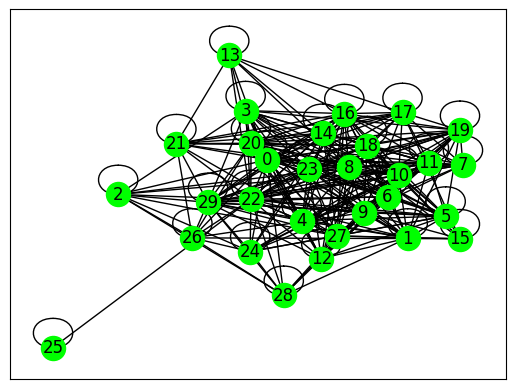

In [17]:
similarity_graph = networkx.from_numpy_array(similarity_matrix)
networkx.draw_networkx(similarity_graph, node_color='lime')

In [18]:
scores = networkx.pagerank(similarity_graph)
ranked_sentences = sorted(
  ((score, index) for index, score in scores.items()),
  reverse=True
)
ranked_sentences[:10]

[(0.040721209316877505, 22),
 (0.039947873723280514, 9),
 (0.03939359424138909, 10),
 (0.037583360907194385, 16),
 (0.03744652515777444, 27),
 (0.037387204944521565, 18),
 (0.03661709582201522, 1),
 (0.03563095404425751, 11),
 (0.035492104383262474, 20),
 (0.035188433076783786, 0)]

In [19]:
num_sentences = 5

top_sentence_indices = [
    ranked_sentences[index][1] for index in range(num_sentences)
]
top_sentence_indices.sort()

summary = ' '.join(np.array(sentences)[top_sentence_indices])
print('\n'.join(wrap(summary, 90)))

By the first century BC, the Roman Empire emerged as the dominant power in the
Mediterranean Basin and became a leading cultural, political and religious centre,
inaugurating the Pax Romana, a period of more than   years during which Italy's law,
technology, economy, art, and literature developed. During the Early Middle Ages, Italy
endured the fall of the Western Roman Empire and barbarian invasions, but by the  th
century numerous rival city-states and maritime republics, mainly in the northern and
central regions of Italy, became prosperous through trade, commerce, and banking, laying
the groundwork for modern capitalism. Centuries of foreign meddling and conquest, and the
rivalry and infighting between the Italian city-states, such as the Italian Wars of the
th and  th centuries, left Italy politically fragmented, and it was further conquered and
divided among multiple foreign European powers over the centuries. Following the rise of
the Italian Resistance and the liberation of Ita

Now we define a function to be able to cleanly display the coincidences between a text and it's summary.

In [9]:
'''
Find the matching substrings in 2 strings.
:parameter
    :param a: string - raw text
    :param b: string - raw text
:return
    2 lists used in to display matches
'''
def utils_split_sentences(a, b):
    ## find clean matches
    match = difflib.SequenceMatcher(isjunk=None, a=a, b=b, autojunk=True)
    lst_match = [block for block in match.get_matching_blocks() if block.size > 20]

    ## difflib didn't find any match
    if len(lst_match) == 0:
        lst_a, lst_b = nltk.sent_tokenize(a), nltk.sent_tokenize(b)

    ## work with matches
    else:
        first_m, last_m = lst_match[0], lst_match[-1]

        ### a
        string = a[0 : first_m.a]
        lst_a = [t for t in nltk.sent_tokenize(string)]
        for n in range(len(lst_match)):
            m = lst_match[n]
            string = a[m.a : m.a+m.size]
            lst_a.append(string)
            if n+1 < len(lst_match):
                next_m = lst_match[n+1]
                string = a[m.a+m.size : next_m.a]
                lst_a = lst_a + [t for t in nltk.sent_tokenize(string)]
            else:
                break
        string = a[last_m.a+last_m.size :]
        lst_a = lst_a + [t for t in nltk.sent_tokenize(string)]

        ### b
        string = b[0 : first_m.b]
        lst_b = [t for t in nltk.sent_tokenize(string)]
        for n in range(len(lst_match)):
            m = lst_match[n]
            string = b[m.b : m.b+m.size]
            lst_b.append(string)
            if n+1 < len(lst_match):
                next_m = lst_match[n+1]
                string = b[m.b+m.size : next_m.b]
                lst_b = lst_b + [t for t in nltk.sent_tokenize(string)]
            else:
                break
        string = b[last_m.b+last_m.size :]
        lst_b = lst_b + [t for t in nltk.sent_tokenize(string)]

    return lst_a, lst_b


'''
Highlights the matched strings in text.
:parameter
    :param a: string - raw text
    :param b: string - raw text
    :param both: bool - search a in b and, if True, viceversa
    :param sentences: bool - if False matches single words
:return
    text html, it can be visualized on notebook with display(HTML(text))
'''
def display_string_matching(a, b, both=True, sentences=True, titles=[]):
    if sentences is True:
        lst_a, lst_b = utils_split_sentences(a, b)
    else:
        lst_a, lst_b = a.split(), b.split()

    ## highlight a
    first_text = []
    for i in lst_a:
        if re.sub(r'[^\w\s]', '', i.lower()) in [re.sub(r'[^\w\s]', '', z.lower()) for z in lst_b]:
            first_text.append('<span style="background-color:rgba(255,215,0,0.3);">' + i + '</span>')
        else:
            first_text.append(i)
    first_text = ' '.join(first_text)

    ## highlight b
    second_text = []
    if both is True:
        for i in lst_b:
            if re.sub(r'[^\w\s]', '', i.lower()) in [re.sub(r'[^\w\s]', '', z.lower()) for z in lst_a]:
                second_text.append('<span style="background-color:rgba(255,215,0,0.3);">' + i + '</span>')
            else:
                second_text.append(i)
    else:
        second_text.append(b)
    second_text = ' '.join(second_text)

    ## concatenate
    if len(titles) > 0:
        first_text = "<strong>"+titles[0]+"</strong><br>"+first_text
    if len(titles) > 1:
        second_text = "<strong>"+titles[1]+"</strong><br>"+second_text
    else:
        second_text = "---"*65+"<br><br>"+second_text
    final_text = first_text +'<br><br>'+ second_text
    return final_text

In [10]:
text = ' '.join(norm_sentences)

highlight_match = display_string_matching(
    text, summary, both=True, sentences=False,
    titles=["Full Text", "Summary"]
)

display(HTML(highlight_match))

EXERCISE: use the *hits* function in networkx or *mutual_info_score* sklearn instead of pagerank scoring

In [20]:
num_sentences = 5

vectorizer = TfidfVectorizer()
dt_matrix = vectorizer.fit_transform(norm_sentences).toarray()

similarity_matrix = np.matmul(dt_matrix, dt_matrix.T)
similarity_graph = networkx.from_numpy_array(similarity_matrix)

scores = networkx.hits(similarity_graph)[1] #Exercise: use hits here
ranked_sentences = sorted(((s, i) for i, s in scores.items()), reverse=True)
ranked_sentences[:10]


top_sentence_indices = [
    ranked_sentences[i][1] for i in range(num_sentences)
]
top_sentence_indices.sort()

second_summary = ' '.join(np.array(sentences)[top_sentence_indices])

highlight_match = display_string_matching(
    summary, second_summary, both=True, sentences=False,
    titles=["Page rank summary", "Hits summary"]
)

display(HTML(highlight_match))

EXERCISE: use *HashingVectorizer* or *BM25* as the vectorizer

In [22]:
num_sentences = 5

vectorizer = HashingVectorizer(n_features=2**4)
dt_matrix = vectorizer.fit_transform(norm_sentences).toarray()

# use sigmoid to normalize similarity matrix
sigmoid = lambda z: 1/(1 + np.exp(-z))

similarity_matrix = sigmoid(np.matmul(dt_matrix, dt_matrix.T))
similarity_graph = networkx.from_numpy_array(similarity_matrix)

scores = networkx.pagerank(similarity_graph)
ranked_sentences = sorted(((s, i) for i, s in scores.items()), reverse=True)
ranked_sentences[:10]


top_sentence_indices = [
    ranked_sentences[i][1] for i in range(num_sentences)
]
top_sentence_indices.sort()

summary = ' '.join(np.array(sentences)[top_sentence_indices])

highlight_match = display_string_matching(
    second_summary, summary, both=True, sentences=False,
    titles=["hits summary (TFIDF)", "page rank summary (hash vectorizer)"]
)

display(HTML(highlight_match))

EXERCISE: choose a vectorizer and a scoring you like

## Larger example

In [23]:
!gdown 'https://drive.google.com/uc?id=1zT0-f5NOKQOuUkiIc29AG2N9upVswC2n'
dtf = pd.read_csv('/content/data_summary.csv')
dtf.head()

Downloading...
From: https://drive.google.com/uc?id=1zT0-f5NOKQOuUkiIc29AG2N9upVswC2n
To: /content/data_summary.csv
100% 84.5M/84.5M [00:00<00:00, 91.1MB/s]


,Unnamed: 0,text,y
0,0,It's official: U.S. President Barack Obama wan...,Syrian official: Obama climbed to the top of t...
1,1,(CNN) -- Usain Bolt rounded off the world cham...,Usain Bolt wins third gold of world championsh...
2,2,"Kansas City, Missouri (CNN) -- The General Ser...",The employee in agency's Kansas City office is...
3,3,Los Angeles (CNN) -- A medical doctor in Vanco...,NEW: A Canadian doctor says she was part of a ...
4,4,(CNN) -- Police arrested another teen Thursday...,Another arrest made in gang rape outside Calif...


In [24]:
i = 1
print("--- Full text ---")
print(dtf["text"].iloc[i])
print(" ")
print("--- Summary ---")
print(dtf["y"].iloc[i])

--- Full text ---
(CNN) -- Usain Bolt rounded off the world championships Sunday by claiming his third gold in Moscow as he anchored Jamaica to victory in the men's 4x100m relay. The fastest man in the world charged clear of United States rival Justin Gatlin as the Jamaican quartet of Nesta Carter, Kemar Bailey-Cole, Nickel Ashmeade and Bolt won in 37.36 seconds. The U.S finished second in 37.56 seconds with Canada taking the bronze after Britain were disqualified for a faulty handover. The 26-year-old Bolt has now collected eight gold medals at world championships, equaling the record held by American trio Carl Lewis, Michael Johnson and Allyson Felix, not to mention the small matter of six Olympic titles. The relay triumph followed individual successes in the 100 and 200 meters in the Russian capital. "I'm proud of myself and I'll continue to work to dominate for as long as possible," Bolt said, having previously expressed his intention to carry on until the 2016 Rio Olympics. Victor

We clean!

In [25]:
def create_stopwords(lst_langs=["english"], lst_add_words=[], lst_keep_words=[]):
    lst_stopwords = set()
    for lang in lst_langs:
        lst_stopwords = lst_stopwords.union(set(nltk.corpus.stopwords.words(lang)))
    lst_stopwords = lst_stopwords.union(lst_add_words)
    lst_stopwords = list(set(lst_stopwords) - set(lst_keep_words))
    return sorted(list(set(lst_stopwords)))

lst_stopwords = create_stopwords(
    lst_langs=['english'],
    lst_add_words=["cnn","say","said","new","wa","ha"]
)
# lst_stopwords = lst_stopwords

def utils_preprocess_text(txt, lst_regex=None, punkt=True, lower=True, slang=True, lst_stopwords=None, stemm=False, lemm=True):
    ## Regex (in case, before cleaning)
    if lst_regex is not None:
        for regex in lst_regex:
            txt = re.sub(regex, '', txt)

    ## Clean
    ### separate sentences with '. '
    txt = re.sub(r'\.(?=[^ \W\d])', '. ', str(txt))
    ### remove punctuations and characters
    txt = re.sub(r'[^\w\s]', '', txt) if punkt is True else txt
    ### strip
    txt = " ".join([word.strip() for word in txt.split()])
    ### lowercase
    txt = txt.lower() if lower is True else txt
    ### slang
    txt = contractions.fix(txt) if slang is True else txt

    ## Tokenize (convert from string to list)
    lst_txt = txt.split()

    ## Stemming (remove -ing, -ly, ...)
    if stemm is True:
        ps = nltk.stem.porter.PorterStemmer()
        lst_txt = [ps.stem(word) for word in lst_txt]

    ## Lemmatization (convert the word into root word)
    if lemm is True:
        lem = nltk.stem.wordnet.WordNetLemmatizer()
        lst_txt = [lem.lemmatize(word) for word in lst_txt]

    ## Stopwords
    if lst_stopwords is not None:
        lst_txt = [word for word in lst_txt if word not in lst_stopwords]

    ## Back to string
    txt = " ".join(lst_txt)
    return txt

def add_preprocessed_text(data, column, lst_regex=None, punkt=False, lower=False, slang=False, lst_stopwords=None, stemm=False, lemm=False, remove_na=True):
    dtf = data.copy()

    ## apply preprocess
    dtf = dtf[ pd.notnull(dtf[column]) ]
    tqdm.pandas(desc='Cleaning text') # lots of cool paramiters you can pass here.
    dtf[column+"_clean"] = dtf[column].progress_apply(lambda x: utils_preprocess_text(x, lst_regex, punkt, lower, slang, lst_stopwords, stemm, lemm))

    ## residuals
    tqdm.pandas(desc='Checking Residuals')
    dtf["check"] = dtf[column+"_clean"].progress_apply(lambda x: len(x))
    if dtf["check"].min() == 0:
        print("--- found NAs ---")
        print(dtf[[column,column+"_clean"]][dtf["check"]==0].head())
        if remove_na is True:
            dtf = dtf[dtf["check"]>0]

    return dtf.drop("check", axis=1)

def add_text_length(data, column):
    dtf = data.copy()
    tqdm.pandas(desc='Word Count')
    dtf['word_count'] = dtf[column].progress_apply(lambda x: len(nltk.word_tokenize(str(x))) )
    tqdm.pandas(desc='Char Count')
    dtf['char_count'] = dtf[column].progress_apply(lambda x: sum(len(word) for word in nltk.word_tokenize(str(x))) )
    tqdm.pandas(desc='Sentence Count')
    dtf['sentence_count'] = dtf[column].progress_apply(lambda x: len(nltk.sent_tokenize(str(x))) )
    dtf['avg_word_length'] = dtf['char_count'] / dtf['word_count']
    dtf['avg_sentence_lenght'] = dtf['word_count'] / dtf['sentence_count']
    print()
    print(dtf[['char_count','word_count','sentence_count','avg_word_length','avg_sentence_lenght']].describe().T[["min","mean","max"]])
    return dtf

In [26]:
!pip install tqdm

In [27]:
from tqdm import tqdm
dtf = add_preprocessed_text(dtf, column="text",
                            punkt=True, lower=True, slang=True, lst_stopwords=lst_stopwords, lemm=True)
dtf = add_preprocessed_text(dtf, column="y",
                            punkt=True, lower=True, slang=True, lst_stopwords=lst_stopwords, lemm=True)
X = add_text_length(dtf, "text_clean")

dtf.head()

Sentence Count: 100%|██████████| 20000/20000 [00:00<00:00, 34325.20it/s]



                            min         mean          max
char_count           103.000000  2260.663000  10038.00000
word_count            19.000000   363.758150   1309.00000
sentence_count         1.000000     1.000000      1.00000
avg_word_length        3.992945     6.211884     35.34507
avg_sentence_lenght   19.000000   363.758150   1309.00000


,Unnamed: 0,text,y,text_clean,y_clean
0,0,It's official: U.S. President Barack Obama wan...,Syrian official: Obama climbed to the top of t...,official president barack obama want lawmaker ...,syrian official obama climbed top tree doe kno...
1,1,(CNN) -- Usain Bolt rounded off the world cham...,Usain Bolt wins third gold of world championsh...,usain bolt rounded world championship sunday c...,usain bolt win third gold world championship a...
2,2,"Kansas City, Missouri (CNN) -- The General Ser...",The employee in agency's Kansas City office is...,kansa city missouri general service administra...,employee agency kansa city office among hundre...
3,3,Los Angeles (CNN) -- A medical doctor in Vanco...,NEW: A Canadian doctor says she was part of a ...,los angeles medical doctor vancouver british c...,canadian doctor part team examining harry burk...
4,4,(CNN) -- Police arrested another teen Thursday...,Another arrest made in gang rape outside Calif...,police arrested another teen thursday sixth su...,another arrest made gang rape outside californ...


In [28]:
i = 1
print("--- Full text ---")
print(dtf["text_clean"][i])
print(" ")
print("--- Summary ---")
print(dtf["y_clean"][i])

--- Full text ---
usain bolt rounded world championship sunday claiming third gold moscow anchored jamaica victory men 4x100m relay fastest man world charged clear united state rival justin gatlin jamaican quartet nesta carter kemar baileycole nickel ashmeade bolt 3736 second finished second 3756 second canada taking bronze britain disqualified faulty handover 26yearold bolt collected eight gold medal world championship equaling record held american trio carl lewis michael johnson allyson felix mention small matter six olympic title relay triumph followed individual success 100 200 meter russian capital proud ill continue work dominate long possible bolt previously expressed intention carry 2016 rio olympics victory never seriously doubt got baton safely hand ashmeade gatlin united state third leg runner rakieem salaam problem gatlin strayed lane struggled get full control baton never able get term bolt earlier jamaica woman underlined dominance sprint event winning 4x100m relay gold a

In [29]:
vectorizer = TfidfVectorizer(min_df=3, max_df=0.5)
vectorizer = vectorizer.fit(dtf.text_clean)

In [33]:
def summarize_doc(corpus, num_sentences=2):
  sentences = nltk.sent_tokenize(corpus)
  norm_sentences = normalize_corpus(sentences)
  dt_matrix = vectorizer.transform(norm_sentences)
  dt_matrix = dt_matrix.toarray() # from sparse to matrix
  similiarity_matrix = np.matmul(dt_matrix, dt_matrix.T)

  similiarity_graph = networkx.from_numpy_array(similiarity_matrix)
  scores = networkx.hits(similiarity_graph)[1]

  ranked_sentences = sorted(((score, index) for index, score in scores.items()),
                            reverse=True)
  # import ipdb
  # ipdb.set_trace()
  top_sentence_indices = [ranked_sentences[index][1] for index in range(num_sentences)]
  top_sentence_indices.sort()

  return ' '.join(np.array(sentences)[top_sentence_indices])

In [34]:
num_sentences = 2
summarize_final = partial(summarize_doc, num_sentences=num_sentences)

dtf_test = dtf.iloc[:1000,:]
tqdm.pandas(desc='Summarizing text')
predicted = dtf_test["text"].progress_apply(summarize_final)

Summarizing text: 100%|██████████| 1000/1000 [00:57<00:00, 17.42it/s]


In [35]:
i = 1
highlight_match = display_string_matching(dtf_test["y"].iloc[i], predicted.iloc[i], both=True, sentences=False,
                                titles=["Real Summary", "Predicted Summary"])
display(HTML(highlight_match))

In [36]:
i = 1
highlight_match = display_string_matching(dtf_test["text"][i], predicted[i], both=True, sentences=True,
                                titles=["Full Text", "Predicted Summary"])
display(HTML(highlight_match))

## Evaluation

One of the best known metrics to evaluate summary quality is Recall-Oriented Understudy for Gisting Evaluation (ROUGE), to automatically assess the quality of a summary by comparing it to human-generated reference summaries. There are several variations of ROUGE, with the most commonly used being: ROUGE-n, ROUGE-L, and ROUGE-S.

In [37]:
def evaluate_summary(y_test, predicted):
    rouge_score = rouge.Rouge()
    scores = rouge_score.get_scores(y_test, predicted, avg=True)
    score_1 = round(scores['rouge-1']['f'], 2)
    score_2 = round(scores['rouge-2']['f'], 2)
    score_L = round(scores['rouge-l']['f'], 2)
    print("rouge1:", score_1, "| rouge2:", score_2, "| rougeL:", score_2,
          "--> avg rouge:", round(np.mean([score_1,score_2,score_L]), 2))

In [38]:
evaluate_summary(dtf_test["y"][i], predicted[i])

rouge1: 0.39 | rouge2: 0.1 | rougeL: 0.1 --> avg rouge: 0.26


EXERCISE: compare with one of the summarization pipelines you defined for the small example and see if you can get a better ROUGE score!

# Abstractive Summarization


Abstractive summarization is a text summarization technique that generates a concise summary by creating new sentences that convey the main ideas of the original text. Unlike extractive summarization, which directly selects sentences or phrases from the source text, abstractive methods aim to produce summaries that are closer to how a human might summarize, often rephrasing or synthesizing information.
Some of its key features are:

- **Generative Approach:** Abstractive summarization involves generating new text that captures the essence of the input while using different phrasing and sentence structures.

- **Contextual Understanding:** Advanced models analyze the text to understand its overall meaning and produce coherent summaries.

- **Flexibility:** This method allows for the integration of knowledge, inference, and rephrasing, making it suitable for summarizing complex and varied content.

In [39]:
!pip install txtai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.7/294.7 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 88.5 MB/s eta 0:00:00


In [40]:
from txtai.pipeline import Summary

Go here: https://huggingface.co/models?pipeline_tag=summarization and chose any model you want, by default it will use a distilbart

In [41]:
summary = Summary('facebook/bart-large-cnn')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


In [42]:
text = ("Search is the base of many applications. Once data starts to pile up, users want to be able to find it. It’s the foundation "
       "of the internet and an ever-growing challenge that is never solved or done. The field of Natural Language Processing (NLP) is "
       "rapidly evolving with a number of new developments. Large-scale general language models are an exciting new capability "
       "allowing us to add amazing functionality quickly with limited compute and people. Innovation continues with new models "
       "and advancements coming in at what seems a weekly basis. This article introduces txtai, an AI-powered search engine "
       "that enables Natural Language Understanding (NLU) based search in any application."
)

summary(text, maxlength=30)

'The field of Natural Language Processing (NLP) is rapidly evolving with a number of new developments. Large-scale general language models are'

In [43]:
i = 0
summarized_text = summary(dtf_test["text"][i], maxlength=40)

In [44]:
highlight_match = display_string_matching(dtf_test["y"][i], summarized_text, both=True, sentences=True,
                                titles=["Summary", "Predicted Summary"])
display(HTML(highlight_match))

In [45]:
highlight_match = display_string_matching(dtf_test["text"][i], summarized_text, both=True, sentences=True,
                                titles=["Full Text", "Predicted Summary"])
display(HTML(highlight_match))

In [46]:
evaluate_summary(dtf_test["y"][i], summarized_text)

rouge1: 0.2 | rouge2: 0.08 | rougeL: 0.08 --> avg rouge: 0.16


EXERCISE: try with another model and see which performs better.